In [1]:
import slab2 as sl
import numpy as np
import matplotlib.pyplot as plt

%matplotlib widget
plt.style.use('dark_background')

In [2]:
A = sl.SlabGuide(symmetric=True, xref)

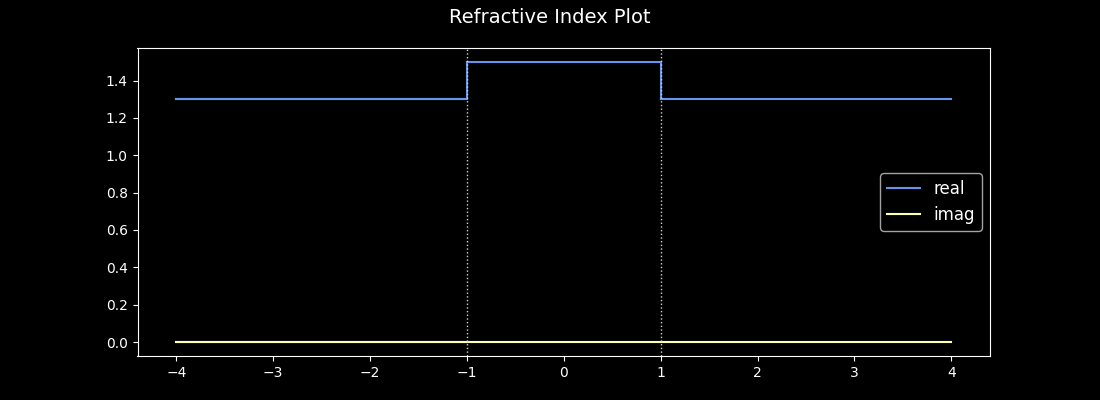

In [3]:
sl.plot_refractive_index(A);

In [4]:
half_width = .5
shift = .25
amplitude = 1

Lx = -half_width + shift
Rx = half_width + shift

def quadratic_piecewise(x):
    x = np.array(x, dtype=float)
    conds = [(x < Lx), ((Lx <= x)*(x <= Rx)), (x > Rx)]
    funcs = [lambda x: 0, lambda x: amplitude * (1 - ((x - shift) / half_width)**2), lambda x: 0]
    return np.piecewise(x, conds, funcs)

f0 = quadratic_piecewise

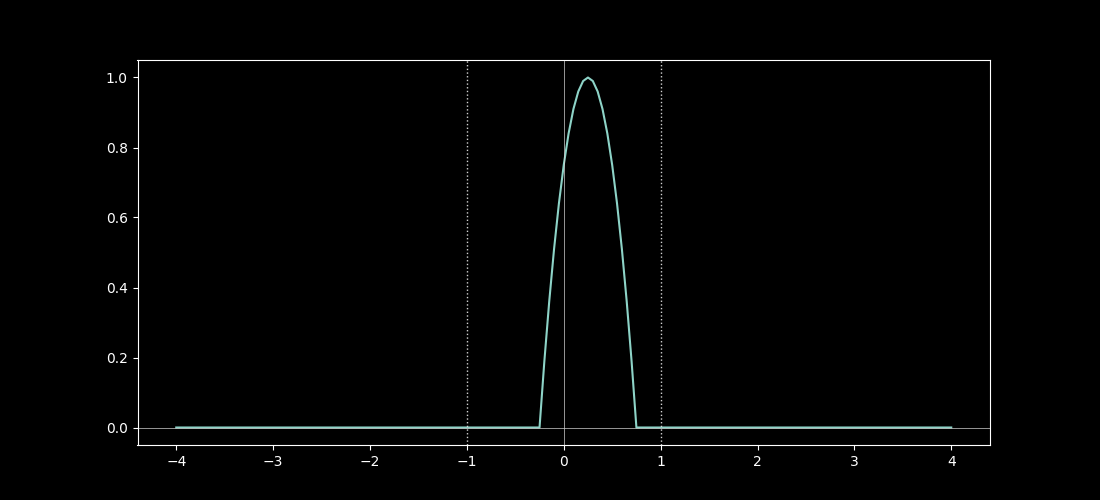

In [5]:
sl.plot_field_1d(A, f0);

In [16]:
P = sl.Propagator(A, f0=f0, Lx=Lx, Rx=Rx)

In [17]:
P.add_contour(sl.real_contour(.0001, A.Z_evanescent, 500))

In [18]:
P.add_contour(sl.real_contour(A.Z_evanescent, 5*A.Z_evanescent, 400))

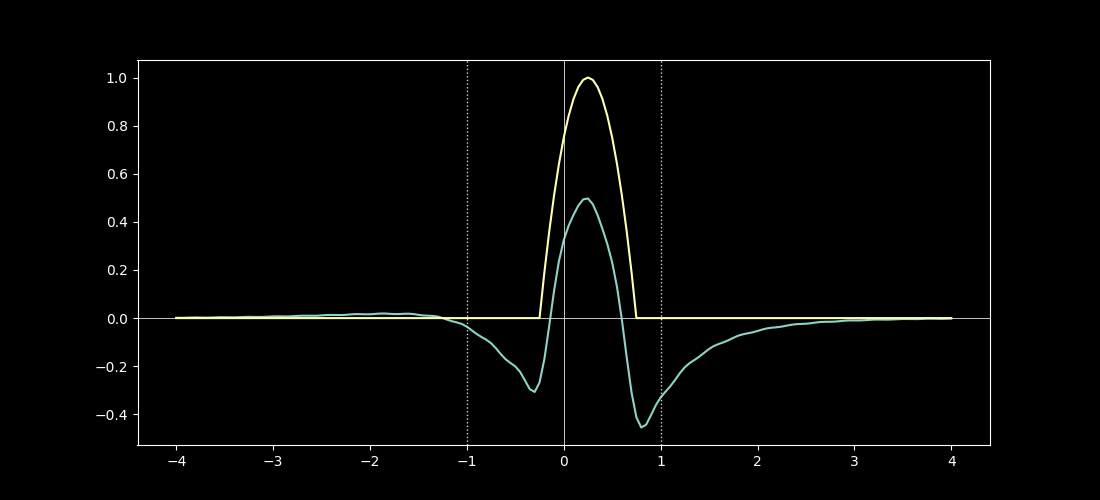

In [19]:
sl.plot_field_1d(A, P);
sl.add_1d_plot(A, f0);

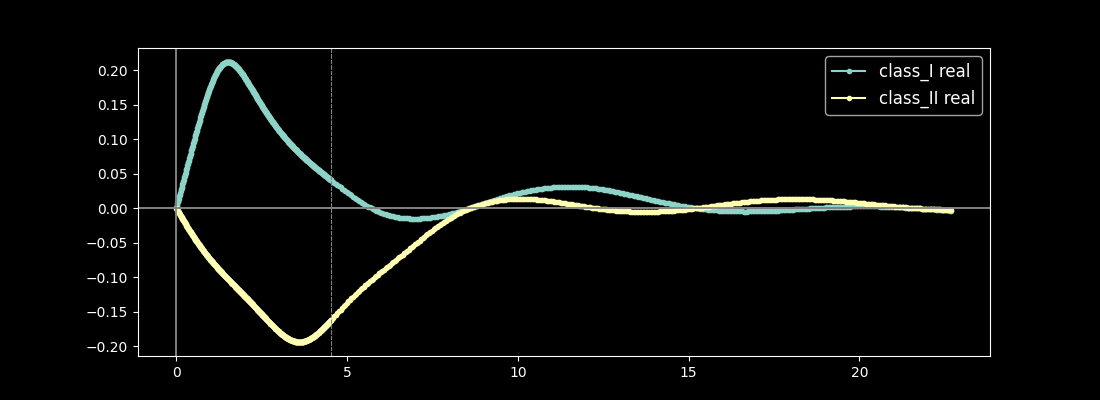

In [20]:
P.plot_transform();